In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


model_index.json: 0.00B [00:00, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Expected types for id2label: (dict[int, str], <class 'NoneType'>), got typing.Dict[str, str].


  0%|          | 0/25 [00:00<?, ?it/s]

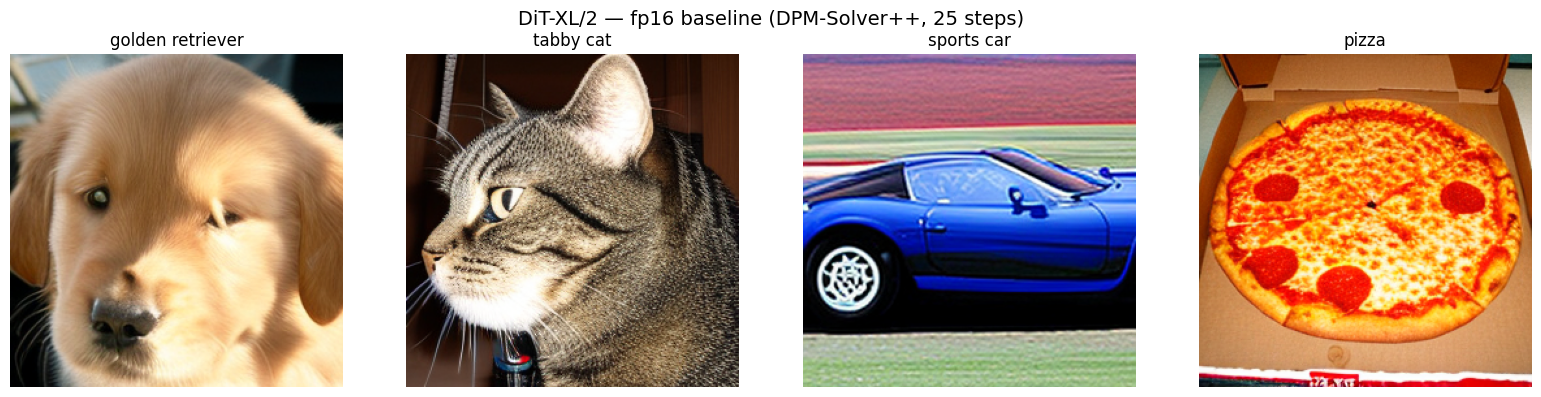

In [2]:
import torch
from diffusers import DiTPipeline, DPMSolverMultistepScheduler
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

pipe = DiTPipeline.from_pretrained(
    "facebook/DiT-XL-2-256",
    torch_dtype = torch.float16,
)

pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)

pipe = pipe.to(device)

# requires integer class indices, not STRINGS
#convers to ImageNet class index internally
# Some common ImageNet indices:
#   207 = golden retriever
#   281 = tabby cat
#   817 = sports car
#   963 = pizza
class_names = ["golden retriever", "tabby cat", "sports car", "pizza"]
class_indices = [207, 281, 817, 963]

#generate
torch.manual_seed(42)

images = pipe(
    class_labels = class_indices,
    num_inference_steps = 25,
    guidance_scale = 4.0,
).images

fig, axes = plt.subplots(1, len(images), figsize=(16,4))
for ax, img, label in zip(axes, images, class_names):
    ax.imshow(img)
    ax.set_title(label, fontsize = 12)
    ax.axis("off")

plt.suptitle("DiT-XL/2 — fp16 baseline (DPM-Solver++, 25 steps)", fontsize=14)
plt.tight_layout()
plt.savefig("dit_baseline_output.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
print(pipe.transformer)

DiTTransformer2DModel(
  (pos_embed): PatchEmbed(
    (proj): Conv2d(4, 1152, kernel_size=(2, 2), stride=(2, 2))
  )
  (transformer_blocks): ModuleList(
    (0-27): 28 x BasicTransformerBlock(
      (norm1): AdaLayerNormZero(
        (emb): CombinedTimestepLabelEmbeddings(
          (time_proj): Timesteps()
          (timestep_embedder): TimestepEmbedding(
            (linear_1): Linear(in_features=256, out_features=1152, bias=True)
            (act): SiLU()
            (linear_2): Linear(in_features=1152, out_features=1152, bias=True)
          )
          (class_embedder): LabelEmbedding(
            (embedding_table): Embedding(1001, 1152)
          )
        )
        (silu): SiLU()
        (linear): Linear(in_features=1152, out_features=6912, bias=True)
        (norm): LayerNorm((1152,), eps=1e-06, elementwise_affine=False)
      )
      (attn1): Attention(
        (to_q): Linear(in_features=1152, out_features=1152, bias=True)
        (to_k): Linear(in_features=1152, out_features=

In [4]:
# Check what's actually available in your torchao version
import torchao
print("torchao version:", torchao.__version__)

import torchao.quantization as tq
print("\nAvailable in torchao.quantization:")
print([x for x in dir(tq) if not x.startswith("_")])

torchao version: 0.10.0

Available in torchao.quantization:
['ALL_AUTOQUANT_CLASS_LIST', 'AffineQuantizedMinMaxObserver', 'AffineQuantizedObserverBase', 'CutlassInt4PackedLayout', 'DEFAULT_AUTOQUANT_CLASS_LIST', 'DEFAULT_FLOAT_AUTOQUANT_CLASS_LIST', 'DEFAULT_INT4_AUTOQUANT_CLASS_LIST', 'DEFAULT_SPARSE_AUTOQUANT_CLASS_LIST', 'FPXWeightOnlyConfig', 'Float8DynamicActivationFloat8SemiSparseWeightConfig', 'Float8DynamicActivationFloat8WeightConfig', 'Float8MMConfig', 'Float8StaticActivationFloat8WeightConfig', 'Float8WeightOnlyConfig', 'GEMLITE_INT4_AUTOQUANT_CLASS_LIST', 'GPTQ', 'GemliteUIntXWeightOnlyConfig', 'Int4DynamicActivationInt4WeightConfig', 'Int4WeightOnlyConfig', 'Int4WeightOnlyGPTQQuantizer', 'Int4WeightOnlyQuantizedLinearWeight', 'Int4WeightOnlyQuantizer', 'Int8DynActInt4WeightGPTQQuantizer', 'Int8DynActInt4WeightLinear', 'Int8DynActInt4WeightQuantizer', 'Int8DynamicActivationInt4WeightConfig', 'Int8DynamicActivationInt8WeightConfig', 'Int8DynamicallyQuantizedLinearWeight', 'I


── fp16_baseline ──


Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Expected types for id2label: (dict[int, str], <class 'NoneType'>), got typing.Dict[str, str].


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

...

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  Avg latency  : 7.46 s
  Peak memory  : 3.49 GB


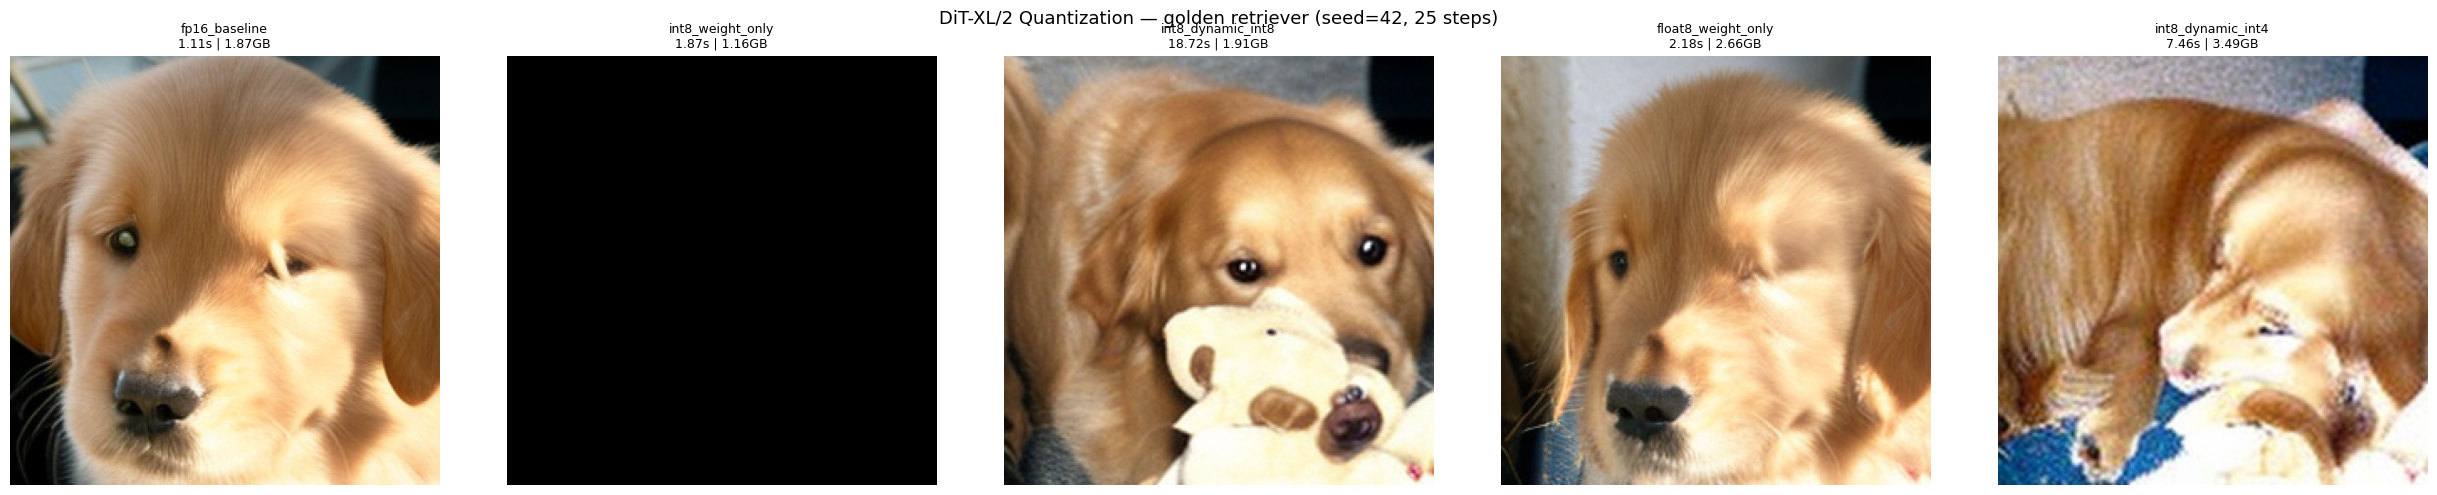



Scheme                     Latency (s)  Peak Mem (GB)     Status
-----------------------------------------------------------------
fp16_baseline                     1.11           1.87         OK
int8_weight_only                  1.87           1.16         OK
int8_dynamic_int8                18.72           1.91         OK
float8_weight_only                2.18           2.66         OK
int8_dynamic_int4                 7.46           3.49         OK


In [5]:
import torch
from torchao.quantization import (
    quantize_,
    Int8WeightOnlyConfig,
    Int8DynamicActivationInt8WeightConfig,
    Float8WeightOnlyConfig,
    Int8DynamicActivationInt4WeightConfig,
)
from diffusers import DiTPipeline, DPMSolverMultistepScheduler
from copy import deepcopy
import matplotlib.pyplot as plt
import time

SEED = 42
CLASS_IDX = 207 
CLASS_NAME = "golden retriever"
NUM_STEPS = 25
GUIDANCE_SCALE = 4.0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_RUNS = 5

def load_pipeline():
    pipe = DiTPipeline.from_pretrained(
        "facebook/DiT-XL-2-256",
        torch_dtype = torch.float16,
    )

    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe = pipe.to(DEVICE)
    return pipe

def benchmark(pipe, num_runs = NUM_RUNS):
    torch.cuda.reset_peak_memory_stats()
    latencies = []
    last_image = None

    for i in range(num_runs):
        torch.manual_seed(SEED)
        torch.cuda.synchronize()
        t0 = time.time()

        output =  pipe(
            class_labels = [CLASS_IDX],
            num_inference_steps = NUM_STEPS,
            guidance_scale = GUIDANCE_SCALE,
        )

        torch.cuda.synchronize()
        latencies.append(time.time() - t0)
        last_image = output.images[0]

    avg_latency = sum(latencies) /num_runs
    peak_mem = torch.cuda.max_memory_allocated() / 1e9

    return last_image, avg_latency, peak_mem

schemes = {
    "fp16_baseline":       None,
    "int8_weight_only":    Int8WeightOnlyConfig(),
    "int8_dynamic_int8":   Int8DynamicActivationInt8WeightConfig(),
    "float8_weight_only":  Float8WeightOnlyConfig(),
    "int8_dynamic_int4":   Int8DynamicActivationInt4WeightConfig(),
}

results = {}

for scheme_name, scheme in schemes.items():
    print(f"\n── {scheme_name} ──")
    pipe = load_pipeline()

    if scheme is not None : 
        try:
            quantize_(pipe.transformer, scheme)
            print(f"  [OK] Quantized successfully")

        except Exception as e:
            print(f"  [FAILED] Quantization error: {e}")
            results[scheme_name] = None
            del pipe
            torch.cuda.empty_cache()
            continue

    try:
        image, latency, peak_mem = benchmark(pipe)
        results[scheme_name] = (image, latency, peak_mem)
        print(f"  Avg latency  : {latency:.2f} s")
        print(f"  Peak memory  : {peak_mem:.2f} GB")
    except Exception as e:
        print(f"  [FAILED] Inference error: {e}")
        results[scheme_name] = None
    finally:
        del pipe
        torch.cuda.empty_cache()

valid = {k: v for k, v in results.items() if v is not None}
n = len(valid)

fig, axes = plt.subplots(1,n, figsize = (5*n, 5))
if n == 1:
    axes = [axes]

for ax, (name, (img, lat, mem)) in zip(axes, valid.items()):
    ax.imshow(img)
    ax.set_title(f"{name}\n{lat:.2f}s | {mem:.2f}GB", fontsize=9)
    ax.axis("off")

plt.suptitle(
    f"DiT-XL/2 Quantization — {CLASS_NAME} (seed={SEED}, {NUM_STEPS} steps)",
    fontsize=13
)
plt.tight_layout()
plt.show()

print("\n")
print(f"{'Scheme':<25} {'Latency (s)':>12} {'Peak Mem (GB)':>14} {'Status':>10}")
print("-" * 65)
for name, val in results.items():
    if val is None:
        print(f"{name:<25} {'—':>12} {'—':>14} {'FAILED':>10}")
    else:
        _, lat, mem = val
        print(f"{name:<25} {lat:>12.2f} {mem:>14.2f} {'OK':>10}")

In [6]:
# Check what happened
print("Results summary:")
for name, val in results.items():
    print(f"  {name}: {'OK' if val is not None else 'FAILED'}")

Results summary:
  fp16_baseline: OK
  int8_weight_only: OK
  int8_dynamic_int8: OK
  float8_weight_only: OK
  int8_dynamic_int4: OK



── fp16_baseline ──


model_index.json: 0.00B [00:00, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-512/snapshots/101a3d462b22d64c4afdd4d0c8c59a2c0b961b99/transformer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-512/snapshots/101a3d462b22d64c4afdd4d0c8c59a2c0b961b99/transformer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-512/snapshots/101a3d462b22d64c4afdd4d0c8c59a2c0b961b99/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-512/snapshots/101a3d462b22d64c4afdd4d0c8c59a2c0b961b99/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Expected types for id2label: (dict[int, str], <class 'NoneType'>), got typing.Dict[str, str].


...

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  Avg latency  : 13.02 s
  Peak memory  : 1.73 GB


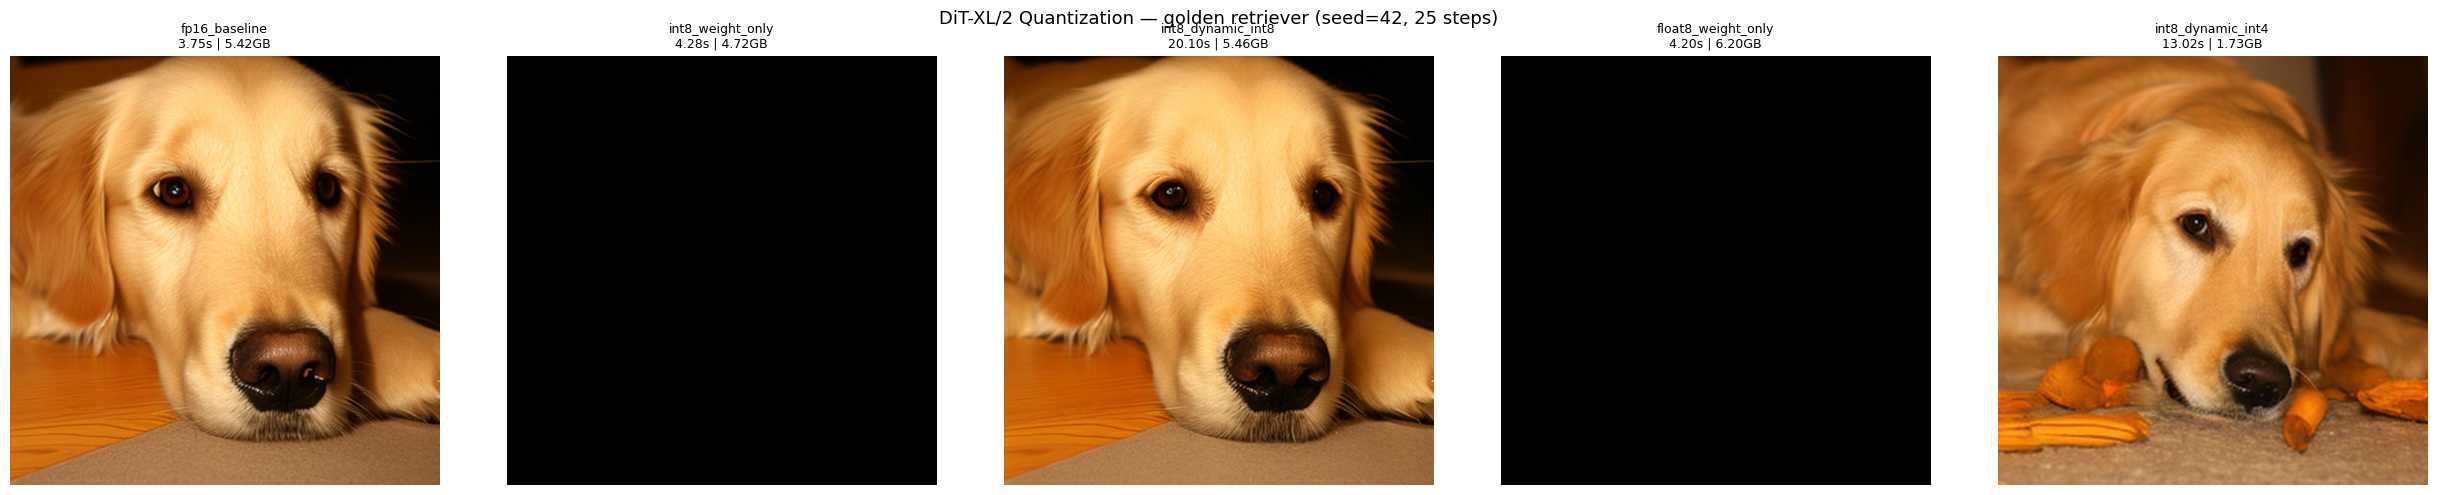



Scheme                     Latency (s)  Peak Mem (GB)     Status
-----------------------------------------------------------------
fp16_baseline                     3.75           5.42         OK
int8_weight_only                  4.28           4.72         OK
int8_dynamic_int8                20.10           5.46         OK
float8_weight_only                4.20           6.20         OK
int8_dynamic_int4                13.02           1.73         OK


In [7]:
import torch
from torchao.quantization import (
    quantize_,
    Int8WeightOnlyConfig,
    Int8DynamicActivationInt8WeightConfig,
    Float8WeightOnlyConfig,
    Int8DynamicActivationInt4WeightConfig,
)
from diffusers import DiTPipeline, DPMSolverMultistepScheduler
from copy import deepcopy
import matplotlib.pyplot as plt
import time

SEED = 42
CLASS_IDX = 207 
CLASS_NAME = "golden retriever"
NUM_STEPS = 25
GUIDANCE_SCALE = 4.0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_RUNS = 5

def load_pipeline():
    pipe = DiTPipeline.from_pretrained(
        "facebook/DiT-XL-2-512",
        torch_dtype = torch.float16,
    )

    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe = pipe.to(DEVICE)
    return pipe

def benchmark(pipe, num_runs = NUM_RUNS):
    torch.cuda.reset_peak_memory_stats()
    latencies = []
    last_image = None

    for i in range(num_runs):
        torch.manual_seed(SEED)
        torch.cuda.synchronize()
        t0 = time.time()

        output =  pipe(
            class_labels = [CLASS_IDX],
            num_inference_steps = NUM_STEPS,
            guidance_scale = GUIDANCE_SCALE,
        )

        torch.cuda.synchronize()
        latencies.append(time.time() - t0)
        last_image = output.images[0]

    avg_latency = sum(latencies) /num_runs
    peak_mem = torch.cuda.max_memory_allocated() / 1e9

    return last_image, avg_latency, peak_mem

schemes = {
    "fp16_baseline":       None,
    "int8_weight_only":    Int8WeightOnlyConfig(),
    "int8_dynamic_int8":   Int8DynamicActivationInt8WeightConfig(),
    "float8_weight_only":  Float8WeightOnlyConfig(),
    "int8_dynamic_int4":   Int8DynamicActivationInt4WeightConfig(),
}

results = {}

for scheme_name, scheme in schemes.items():
    print(f"\n── {scheme_name} ──")
    pipe = load_pipeline()

    if scheme is not None : 
        try:
            quantize_(pipe.transformer, scheme)
            print(f"  [OK] Quantized successfully")

        except Exception as e:
            print(f"  [FAILED] Quantization error: {e}")
            results[scheme_name] = None
            del pipe
            torch.cuda.empty_cache()
            continue

    try:
        image, latency, peak_mem = benchmark(pipe)
        results[scheme_name] = (image, latency, peak_mem)
        print(f"  Avg latency  : {latency:.2f} s")
        print(f"  Peak memory  : {peak_mem:.2f} GB")
    except Exception as e:
        print(f"  [FAILED] Inference error: {e}")
        results[scheme_name] = None
    finally:
        del pipe
        torch.cuda.empty_cache()

valid = {k: v for k, v in results.items() if v is not None}
n = len(valid)

fig, axes = plt.subplots(1,n, figsize = (5*n, 5))
if n == 1:
    axes = [axes]

for ax, (name, (img, lat, mem)) in zip(axes, valid.items()):
    ax.imshow(img)
    ax.set_title(f"{name}\n{lat:.2f}s | {mem:.2f}GB", fontsize=9)
    ax.axis("off")

plt.suptitle(
    f"DiT-XL/2 Quantization — {CLASS_NAME} (seed={SEED}, {NUM_STEPS} steps)",
    fontsize=13
)
plt.tight_layout()
plt.show()

print("\n")
print(f"{'Scheme':<25} {'Latency (s)':>12} {'Peak Mem (GB)':>14} {'Status':>10}")
print("-" * 65)
for name, val in results.items():
    if val is None:
        print(f"{name:<25} {'—':>12} {'—':>14} {'FAILED':>10}")
    else:
        _, lat, mem = val
        print(f"{name:<25} {lat:>12.2f} {mem:>14.2f} {'OK':>10}")